# Сокращение размерности

В каждом из заданий:
* Обучите два классификатора (svm и логистическую регрессию на датасете данном ниже) в датасете размерность из 30 признаков
* Попребирайте различное количество итоговых размерностей и постройте графики качества от количества размерностей. Выведите обе модели на одном графике в каждой заадче

In [4]:
import numpy as np
import sklearn
import matplotlib.pyplot as plt
from sklearn import decomposition
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
np.random.seed(5)
dataset = datasets.load_breast_cancer()
scaler = StandardScaler()

# Lasso regularization (2pts)

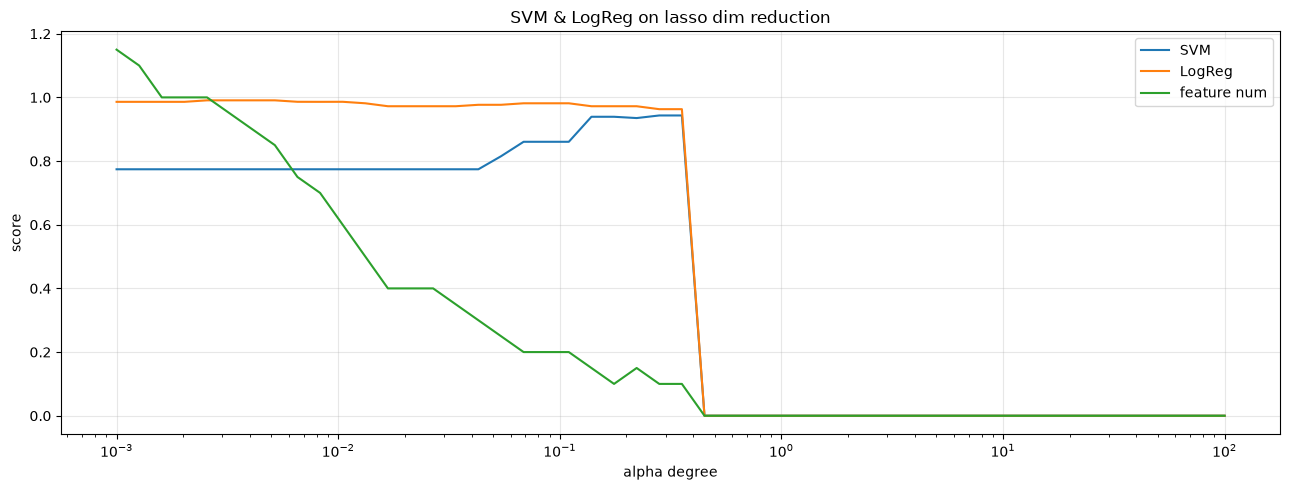

In [ ]:
x = scaler.fit_transform(dataset.data)
y = dataset.target

svm_score = []
logreg_score = []
feature_num = []

for a in np.logspace(-3, 2, 50):
    lasso_model = Lasso(alpha=a).fit(x, y)
    x_selected = np.delete(x, np.where(lasso_model.coef_ == 0)[0], axis=1)
    feature_num.append(x_selected.shape[1]/20)
    if x_selected.shape[1] == 0:
        svm_score.append(0.5)
        logreg_score.append(0.5)
        continue
    x_train, x_test, y_train, y_test = train_test_split(x_selected, y, train_size=0.7, random_state=42)

    svm = SVC(C=1e-2, kernel="rbf", degree=3).fit(x_train, y_train)
    logreg = LogisticRegression().fit(x_train, y_train)

    svm_pred = svm.predict(x_test)
    logreg_pred = logreg.predict(x_test)

    svm_f1 = f1_score(y_test, svm_pred)
    logreg_f1 = f1_score(y_test, logreg_pred)

    svm_score.append(svm_f1)
    logreg_score.append(logreg_f1)

figure, axis = plt.subplots(1, 1, figsize=(13, 5))

axis.plot(np.logspace(-3, 2, 50), svm_score, label = "SVM")
axis.plot(np.logspace(-3, 2, 50), logreg_score, label = "LogReg")
axis.plot(np.logspace(-3, 2, 50), feature_num, label = "feature num")
axis.set_title("SVM & LogReg on lasso dim reduction")
axis.set_xlabel("alpha degree")
axis.set_xscale("log")
axis.set_ylabel("score")
axis.grid(True, alpha=0.3)
axis.legend()

figure.tight_layout()
plt.show()

# Forward selection (2pts)

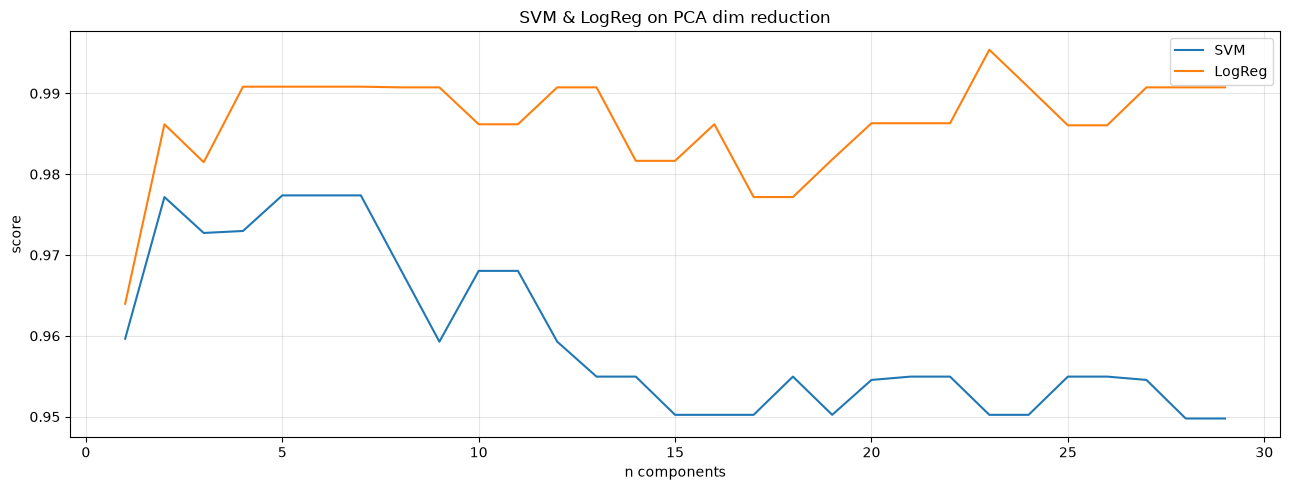

In [6]:
x = scaler.fit_transform(dataset.data)
y = dataset.target

svm_score = []
logreg_score = []

for n in range(1, x.shape[1]):
    selector_model = LogisticRegression()
    fs = SequentialFeatureSelector(selector_model, direction="forward", n_features_to_select=n)
    x_selected = fs.fit_transform(x, y)
    x_train, x_test, y_train, y_test = train_test_split(x_selected, y, train_size=0.7, random_state=42)

    svm = SVC(C=1e-1, kernel="rbf", degree=3).fit(x_train, y_train)
    logreg = LogisticRegression().fit(x_train, y_train)

    svm_pred = svm.predict(x_test)
    logreg_pred = logreg.predict(x_test)

    svm_f1 = f1_score(y_test, svm_pred)
    logreg_f1 = f1_score(y_test, logreg_pred)

    svm_score.append(svm_f1)
    logreg_score.append(logreg_f1)

figure, axis = plt.subplots(1, 1, figsize=(13, 5))

axis.plot(list(range(1, x.shape[1])), svm_score, label = "SVM")
axis.plot(list(range(1, x.shape[1])), logreg_score, label = "LogReg")
axis.set_title("SVM & LogReg on PCA dim reduction")
axis.set_xlabel("n components")
axis.set_ylabel("score")
axis.grid(True, alpha=0.3)
axis.legend()

figure.tight_layout()
plt.show()

# Backward elimination (2pts)

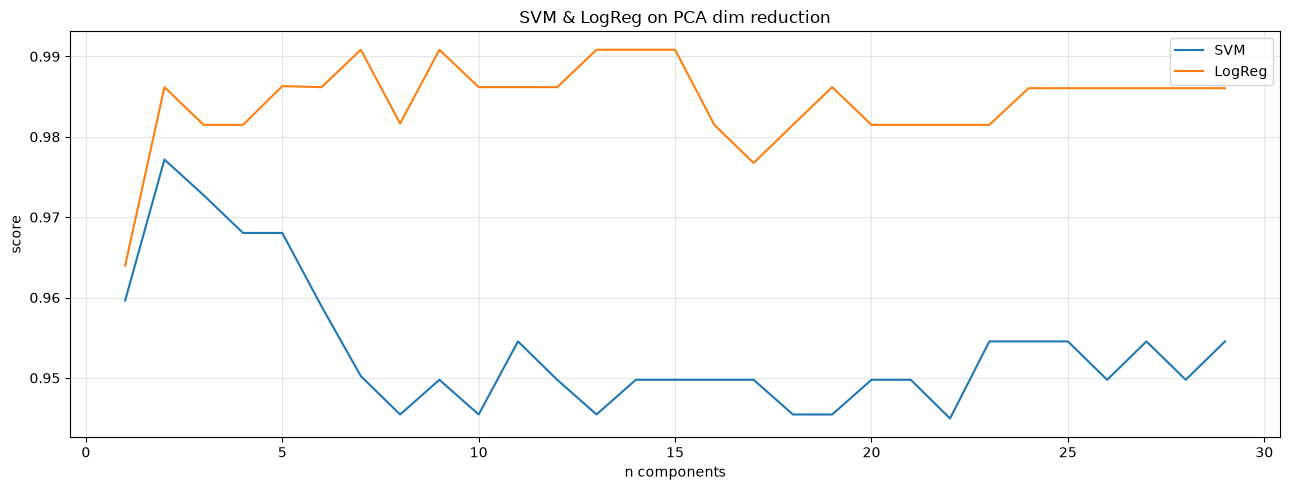

In [7]:
x = scaler.fit_transform(dataset.data)
y = dataset.target

svm_score = []
logreg_score = []

for n in range(1, x.shape[1]):
    selector_model = LogisticRegression()
    fs = SequentialFeatureSelector(selector_model, direction="backward", n_features_to_select=n)
    x_selected = fs.fit_transform(x, y)
    x_train, x_test, y_train, y_test = train_test_split(x_selected, y, train_size=0.7, random_state=42)

    svm = SVC(C=1e-1, kernel="rbf", degree=3).fit(x_train, y_train)
    logreg = LogisticRegression().fit(x_train, y_train)

    svm_pred = svm.predict(x_test)
    logreg_pred = logreg.predict(x_test)

    svm_f1 = f1_score(y_test, svm_pred)
    logreg_f1 = f1_score(y_test, logreg_pred)

    svm_score.append(svm_f1)
    logreg_score.append(logreg_f1)

figure, axis = plt.subplots(1, 1, figsize=(13, 5))

axis.plot(list(range(1, x.shape[1])), svm_score, label = "SVM")
axis.plot(list(range(1, x.shape[1])), logreg_score, label = "LogReg")
axis.set_title("SVM & LogReg on PCA dim reduction")
axis.set_xlabel("n components")
axis.set_ylabel("score")
axis.grid(True, alpha=0.3)
axis.legend()

figure.tight_layout()
plt.show()

# PCA (2 pts)


### EM алгоритм

Оставлю это тут просто чтобы пугать людей


$$
\log p(x|\theta) = \int q(z)\log p(x|\theta)dz = \int q(z)\log\dfrac{p(x,z|\theta)}{p(z|x,\theta)}dz = \int q(z)\log\dfrac{p(x,z|\theta)}{q(z)}dz+\int q(z)\log\dfrac{q(z)}{p(z|x,\theta)}dz = \mathcal{L}(q,\theta)+KL(q(z)|p(z|x,\theta))
$$

** E-step **
$$ q(z)^{(n+1)} = p(z|x,\theta^{(n)}) $$
** M-step **
$$ \theta^{(n+1)} = \max\limits_{\theta} \mathcal{L}(q^{(n+1)},\theta) $$

Обучите два классификатора (svm и огистическую регрессию на датасете данном ниже) в датасете размерность из 30 признаков. Попребирайте различное количество итоговых размерностей (до которых будет сокращать PCA) и постройте графики для обоих классификаторов. Сделайте выводы.

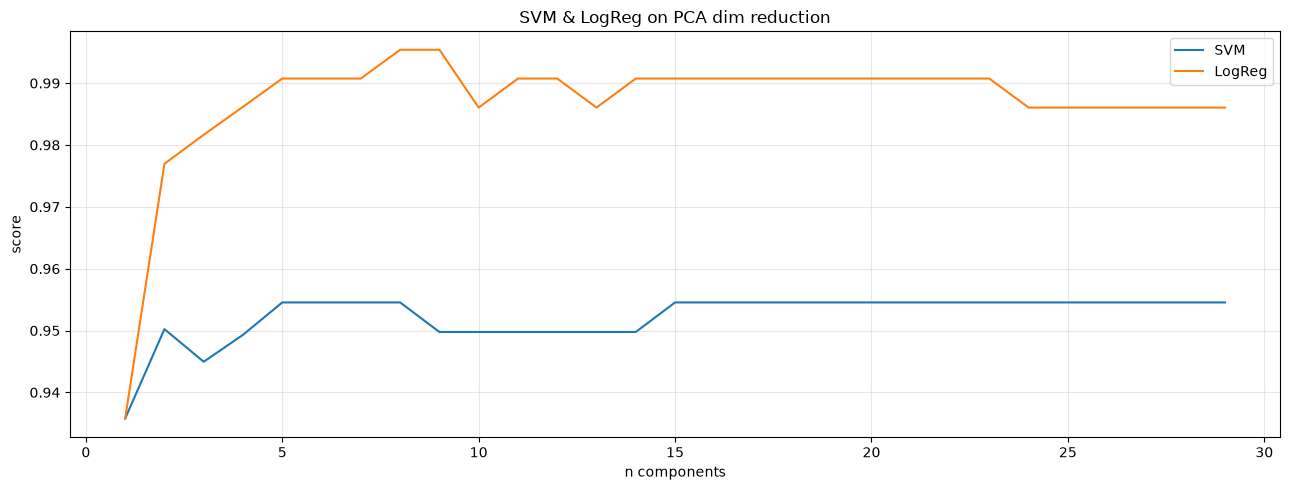

In [8]:
x = scaler.fit_transform(dataset.data)
y = dataset.target

svm_score = []
logreg_score = []

for n in range(1, x.shape[1]):
    pca = PCA(n_components=n, random_state=42)
    x_pca= pca.fit_transform(x)
    x_train, x_test, y_train, y_test = train_test_split(x_pca, y, train_size=0.7, random_state=42)

    svm = SVC(C=1e-1, kernel="rbf", degree=3).fit(x_train, y_train)
    logreg = LogisticRegression().fit(x_train, y_train)

    svm_pred = svm.predict(x_test)
    logreg_pred = logreg.predict(x_test)

    svm_f1 = f1_score(y_test, svm_pred)
    logreg_f1 = f1_score(y_test, logreg_pred)

    svm_score.append(svm_f1)
    logreg_score.append(logreg_f1)

figure, axis = plt.subplots(1, 1, figsize=(13, 5))

axis.plot(list(range(1, x.shape[1])), svm_score, label = "SVM")
axis.plot(list(range(1, x.shape[1])), logreg_score, label = "LogReg")
axis.set_title("SVM & LogReg on PCA dim reduction")
axis.set_xlabel("n components")
axis.set_ylabel("score")
axis.grid(True, alpha=0.3)
axis.legend()

figure.tight_layout()
plt.show()
    


#  Выводы (2pts)

В среднем, LogReg требует меньше признаков для хорошого скора и сам по себе имеет скор всегда выше, и при увеличении кол-ва признаков SVM быстрее падает, ну и на Forward Selection скор SVM падает медленне